# Are longer arguments more persuasive?

This analysis uses three features from the **top-level opening reply**: word count, sentence count, and average words per sentence. The outcome is the branch's first verified OP delta in the seven days after hour one, among branches still eligible at that cutoff. We use the published training split and the same three discussion-grouped folds as M0. Each discussion stays together in one fold.

The [standalone training script](train_argument_length.py) saves each run in a timestamped directory. The notebook opens the latest run by default. Set `RUN_ID` to review an earlier run. Run with pandas, NumPy, scikit-learn, and Matplotlib available in the kernel.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "team-setup").is_dir() and (path / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/argument-length/1h"
SCRIPT = REPO / "project/notebooks/models/argument-length/train_argument_length.py"
RUN_ID = None


def available_runs():
    return sorted(path for path in RUNS.glob("*/results.json"))


if RUN_ID is None and not available_runs():
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else available_runs()[-1]
report = json.loads(report_path.read_text())
predictions = pd.read_parquet(report_path.parent / "training_oof_predictions.parquet")
print("Run:", report_path.parent.name)
print(f"Eligible branches: {report['eligible_branches']:,}")
print(f"Excluded because opening length could not be measured: {report['excluded_unusable_openings']:,}")
display(predictions[[
    "branch_id", "word_count", "sentence_count", "average_sentence_length", "delta_after_1h",
]].head())

Run: 20261120T191518464655Z
Eligible branches: 211,192
Excluded because opening length could not be measured: 9,342


,branch_id,word_count,sentence_count,average_sentence_length,delta_after_1h
0,t1_c8778bp,79,7,11.285714,0
1,t1_c877amv,5,1,5.000000,0
2,t1_c879vyu,164,7,23.428571,0
3,t1_c87bu7k,68,4,17.000000,0
4,t1_c87cmce,120,4,30.000000,0


## Observed delta rate by opening length

Word count uses the same cleaned openings as M0. Quoted lines and clearly marked edits are removed. Sentence counts use terminal punctuation and blank lines as approximate boundaries. Average sentence length is the word count divided by sentence count. Unavailable openings are excluded from both the descriptive comparison and the classifier.

The groups contain roughly equal numbers of branches. The intervals resample whole discussions. These are descriptive rates and can also reflect differences in what the openings argue, when they were posted, or how the OP engaged.

In [2]:
ranges = pd.DataFrame(report["word_count_ranges"])
ranges["word_count_range"] = ranges.apply(lambda row: f"{int(row['min_words'])}–{int(row['max_words'])}", axis=1)
rates = ranges.set_index("word_count_range")[[
    "branches", "later_deltas", "later_delta_rate", "ci_lower", "ci_upper",
]].copy()
rates[["later_delta_rate", "ci_lower", "ci_upper"]] *= 100
display(rates.rename(columns={
    "later_delta_rate": "later delta rate (%)", "ci_lower": "95% CI lower (%)",
    "ci_upper": "95% CI upper (%)",
}).round(3))

,branches,later_deltas,later delta rate (%),95% CI lower (%),95% CI upper (%)
word_count_range,,,,,
1–35,40389,318,0.787,0.690,0.871
36–70,40445,428,1.058,0.965,1.162
71–119,40476,602,1.487,1.379,1.603
120–207,40383,893,2.211,2.061,2.359
208–1879,40157,1469,3.658,3.458,3.882


## Three-fold classifier

The model is L2-regularized logistic regression with a fixed `C=1`. Within each fold, the pipeline applies `log1p` and learns scaling on the fitting rows. Each probability below comes from a model fitted on other discussions. Average precision is compared with the outcome prevalence of the analyzed cohort. The length features are related by construction, so individual coefficients would be hard to interpret as independent evidence about persuasion.

In [3]:
metrics = pd.DataFrame([*report["folds"], {"fold": "Pooled", **report["pooled_out_of_fold"]}])
metrics = metrics.set_index("fold")
metrics[["prevalence", "average_precision"]] *= 100
display(metrics.rename(columns={"prevalence": "prevalence (%)", "average_precision": "average precision (%)"}).round(4))

,branches,later_deltas,prevalence (%),average precision (%),roc_auc,brier_score
fold,,,,,,
1,67317,1240,1.8420,3.5938,0.6620,0.0180
2,67275,1232,1.8313,3.5646,0.6560,0.0179
3,67258,1238,1.8407,3.4595,0.6645,0.0180
Pooled,201850,3710,1.8380,3.5204,0.6608,0.0179


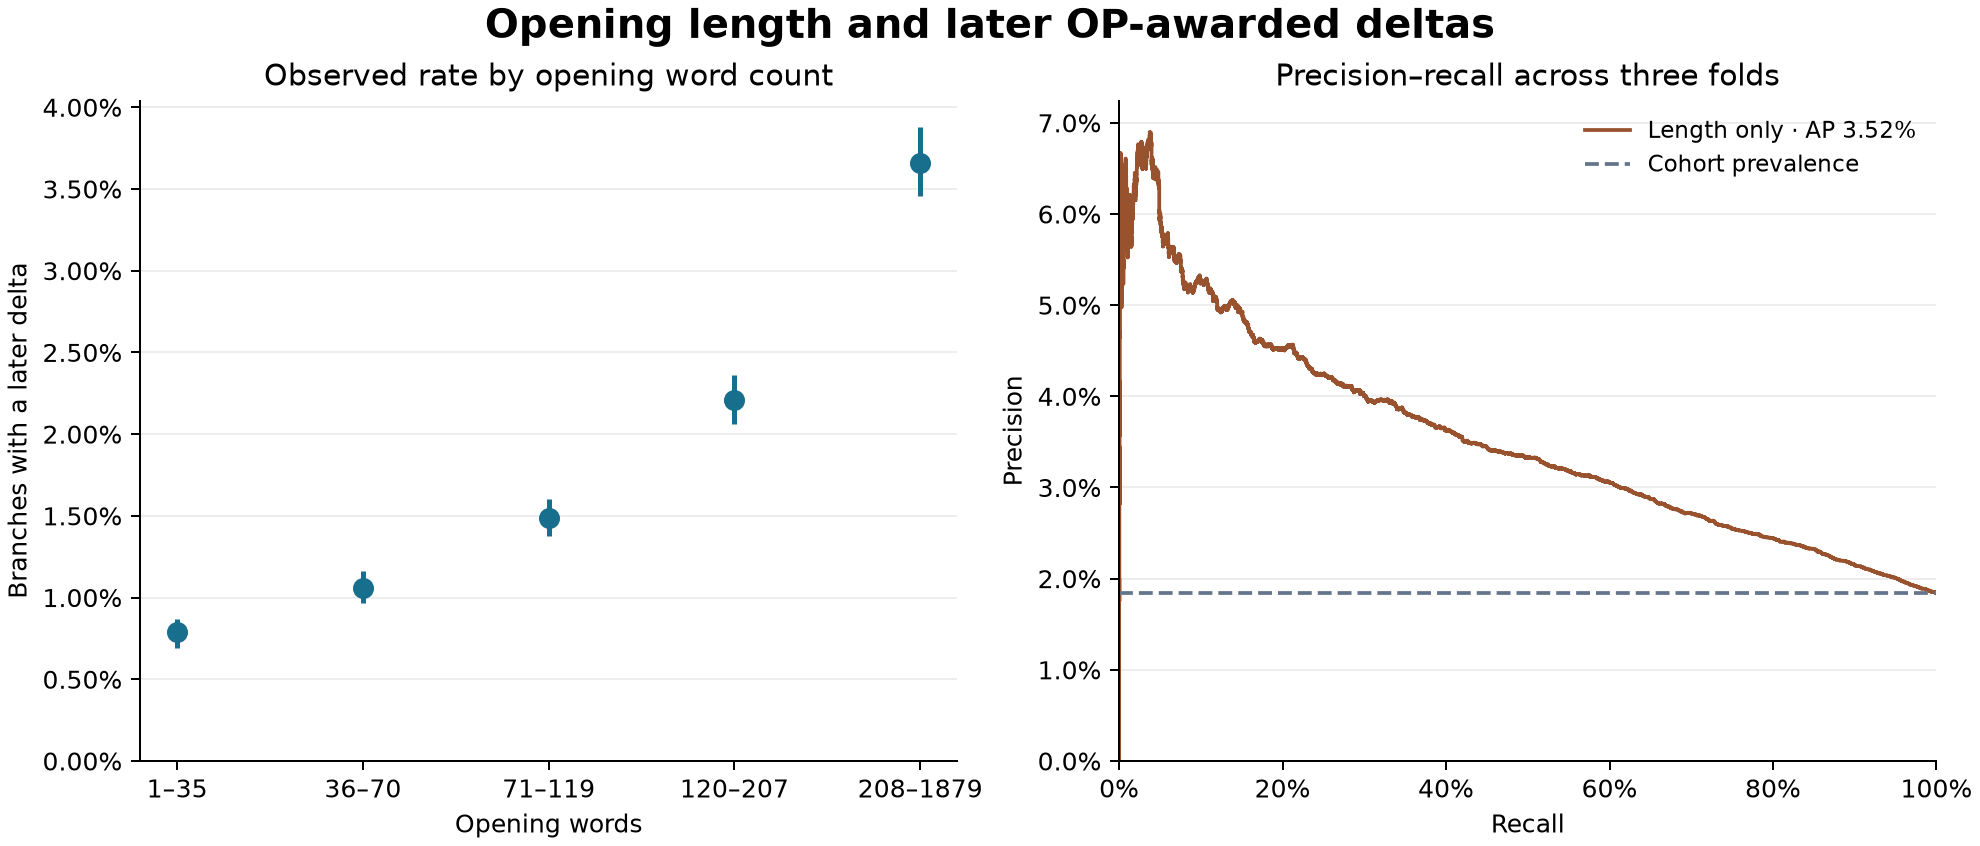

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import precision_recall_curve


fig, (rate_ax, pr_ax) = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
fig.suptitle("Opening length and later OP-awarded deltas", fontsize=16, weight="bold")
x = np.arange(len(rates))
rate_ax.vlines(x, rates["ci_lower"], rates["ci_upper"], color="#176e8d", linewidth=2)
rate_ax.scatter(x, rates["later_delta_rate"], color="#176e8d", s=55, zorder=3)
rate_ax.set_xticks(x, rates.index.tolist())
rate_ax.set(title="Observed rate by opening word count", xlabel="Opening words",
            ylabel="Branches with a later delta")
rate_ax.set_ylim(bottom=0)
rate_ax.yaxis.set_major_formatter(PercentFormatter(100))

y = predictions["delta_after_1h"]
precision, recall, _ = precision_recall_curve(y, predictions["argument_length_probability"])
ap = report["pooled_out_of_fold"]["average_precision"]
pr_ax.step(recall[:-1], 100 * precision[:-1], where="post", color="#98522d", label=f"Length only · AP {ap:.2%}")
pr_ax.axhline(100 * y.mean(), color="#64758b", linestyle="--", label="Cohort prevalence")
pr_ax.set(xlim=(0, 1), ylim=(0, None), title="Precision–recall across three folds",
          xlabel="Recall", ylabel="Precision")
pr_ax.xaxis.set_major_formatter(PercentFormatter(1))
pr_ax.yaxis.set_major_formatter(PercentFormatter(100))
pr_ax.legend(frameon=False, fontsize=9)
for ax in (rate_ax, pr_ax):
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.savefig(report_path.parent / "argument_length_results.png", dpi=180, facecolor="white")
plt.show()